# The Etymological DNA of *Moby-Dick*
### A crawler-based study of word origins in Herman Melville's vocabulary

**Student:** Hasnain Saleem Khan · **Instructor:** Daria Popova · **Course:** Linguistic Data: Quantitative Analysis and Visualisation · October 2026

---

**Idea.** English vocabulary is layered: an inherited Germanic core, a large French layer after the Norman Conquest, Latin and Greek borrowings from learned writing, and smaller contributions from seafaring neighbours (Old Norse, Dutch). This project measures these layers in one long literary text. A **web crawler** traces the ~2,000 most frequent content words of *Moby-Dick* through Wiktionary, page by page, back to their oldest recorded ancestor. The resulting etymological database is used to test five hypotheses.

| | Hypothesis | Test (step) |
|---|---|---|
| **H1** | *Frequency*: frequent words are mostly Germanic, rarer words mostly Latin/French/Greek | correlation & regression of origin on log frequency (4) |
| **H2** | *Style*: the expository "whale-science" chapters are more Latinate than the narrative chapters | chapter profiles, PCA, clustering, Mann–Whitney U (5) |
| **H3** | *Topic*: maritime/whaling vocabulary has a different origin profile, with more seafaring (Norse, Dutch) loans | χ² test on a nautical word set (4) |
| **H4** | *Network*: ancestry chains form communities that match language families, with Old French / Latin as bridges | networkx centrality and greedy-modularity communities (6) |
| **H5** | *Form vs. meaning*: origin is predictable from spelling, much less from meaning | character n-gram TF-IDF vs. word2vec classifiers (7) |

**Pipeline.** Step 1 word list and chapters → Step 2 crawler → Step 3 cleaning, classification and SQLite database → Steps 4–7 analyses → summary of results and conclusions.

In [1]:
import os, re, sys, json, sqlite3, subprocess, collections, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import spacy
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from gensim.models import Word2Vec
from networkx.algorithms import community as nx_comm

from crawler.languages import classify_chain, name as lang_name, stratum_of_code, STRATA, LATINATE, LANGUAGES

pd.set_option("display.max_colwidth", 80)
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.family": "DejaVu Sans",
                     "axes.spines.top": False, "axes.spines.right": False})

# one colour per etymological stratum, used in every figure
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
COLORS = {"Germanic (native)": "#2a78d6", "French": "#eb6834", "Latin": "#1baf7a", "Greek": "#eda100",
          "Old Norse": "#e87ba4", "Dutch/Low German": "#008300", "Other Romance": "#4a3aa7",
          "Other": "#a8a69e", "unknown": "#e1e0d9"}
def style(ax, title, xlabel=None, ylabel=None, grid="x"):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    if xlabel: ax.set_xlabel(xlabel, color=MUTED)
    if ylabel: ax.set_ylabel(ylabel, color=MUTED)
    ax.tick_params(colors=INK2, labelsize=9)
    if grid: getattr(ax, f"{grid}axis").grid(True, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
def save(fig, name):
    fig.patch.set_facecolor(SURFACE); fig.tight_layout(); fig.savefig(f"figures/{name}", facecolor=SURFACE); plt.show()
print("spaCy", spacy.__version__, "| networkx", nx.__version__)

spaCy 3.8.16 | networkx 3.6.1


## Step 1. Word list and text segmentation

**What:** select the words to be traced, and split the novel into chapters.
**How:** the Project Gutenberg text is cut at its `CHAPTER n` headings (135 chapters; the Epilogue is left out). Every chapter is lemmatized and POS-tagged with spaCy. The word list consists of the **2,000 most frequent content lemmas**: nouns, verbs, adjectives and adverbs, without stop words, one-letter tokens and archaic pronouns such as *thou, ye*.

Each chapter is also labelled **expository** or **narrative**. Expository chapters are the essay-like chapters that describe whales and whaling instead of advancing the plot, e.g. *Cetology*, the chapters on whale pictures, the whale's head, skeleton, tail, ambergris and fossil whales. The labels were assigned by hand from the chapter titles and contents (list below).

In [2]:
raw = open("data/moby_dick.txt", encoding="utf-8").read()
parts = re.split(r"^CHAPTER (\d+)\n", raw, flags=re.M)
chapters = {}
for i in range(1, len(parts), 2):
    n, body = int(parts[i]), parts[i + 1].split("\nEpilogue")[0]
    chapters[n] = (body.strip().split("\n")[0].strip(), body)

EXPOSITORY = {24, 25, 32, 42, 45, 55, 56, 57, 58, 60, 62, 63, 65, 68, 74, 75, 76, 77, 79, 80, 82, 83,
              85, 86, 88, 89, 90, 92, 101, 102, 103, 104, 105}
print(f"{len(chapters)} chapters, {len(EXPOSITORY)} labelled expository, e.g.:")
print(" | ".join(f"{n} {chapters[n][0]}" for n in sorted(EXPOSITORY)[:12]), "...")

135 chapters, 33 labelled expository, e.g.:
24 The Advocate. | 25 Postscript. | 32 Cetology. | 42 The Whiteness of The Whale. | 45 The Affidavit. | 55 Of the Monstrous Pictures of Whales. | 56 Of the Less Erroneous Pictures of Whales, and the True Pictures of | 57 Of Whales in Paint; in Teeth; in Wood; in Sheet-Iron; in Stone; in | 58 Brit. | 60 The Line. | 62 The Dart. | 63 The Crotch. ...


In [3]:
nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])
rows = []
for n, (title, body) in chapters.items():
    paragraphs = [re.sub(r"\s+", " ", p).strip() for p in re.split(r"\n\s*\n", body) if p.strip()]
    for doc in nlp.pipe(paragraphs, batch_size=64):
        rows += [(n, t.lemma_.lower(), t.pos_, t.is_stop) for t in doc if t.is_alpha]
tokens = pd.DataFrame(rows, columns=["chapter", "lemma", "pos", "stop"])

ARCHAIC = {"thou", "thee", "thy", "thine", "ye", "yea", "nay", "aye", "ah", "oh"}
content = tokens[tokens.pos.isin({"NOUN", "VERB", "ADJ", "ADV"}) & ~tokens.stop
                 & (tokens.lemma.str.len() > 1) & ~tokens.lemma.isin(ARCHAIC)]
wordlist = (content.groupby("lemma")
            .agg(freq=("lemma", "size"), pos=("pos", lambda s: s.mode()[0]))
            .sort_values("freq", ascending=False).head(2000).reset_index())
wordlist.to_csv("data/wordlist.csv", index=False)

chap = pd.DataFrame([(n, t, "expository" if n in EXPOSITORY else "narrative") for n, (t, _) in chapters.items()],
                    columns=["chapter", "title", "type"]).set_index("chapter")
chap["tokens"] = tokens.groupby("chapter").size()
print(f"{len(tokens):,} word tokens; {content.lemma.nunique():,} distinct content lemmas; word list = {len(wordlist)} lemmas")
print(f"the word list covers {content.lemma.isin(wordlist.lemma).mean():.1%} of all content-word tokens")
wordlist.head(10).T

210,357 word tokens; 11,136 distinct content lemmas; word list = 2000 lemmas
the word list covers 75.4% of all content-word tokens


,0,1,2,3,4,5,6,7,8,9
lemma,whale,man,ship,sea,boat,head,old,time,come,say
freq,1142,758,603,489,465,439,439,439,403,366
pos,NOUN,NOUN,NOUN,NOUN,NOUN,NOUN,ADJ,NOUN,VERB,VERB


## Step 2. The etymology crawler

**What:** collect the ancestry chain of every word in the list from **Wiktionary**.
**How:** the crawler (`crawler/wiktionary_crawler.py`) works like a reader clicking through Wiktionary:

1. it opens the page of a word (e.g. *harpoon*) and scrapes the **Etymology** section of the *English* entry;
2. it reads Wiktionary's etymology templates (`{{inh}}` inherited, `{{bor}}` borrowed, `{{der}}` derived, `{{lbor}}` learned borrowing, and the older `{{etyl}}` + `{{m}}`) and records each ancestor (language, word, relation). Cognates and doublets are ignored;
3. it **follows the link to the oldest ancestor** on that page (*harpoon* → French *harpon*), opens that page, scrapes the ancestor's own etymology in the right language section, and continues until no further ancestor is given (max. depth 6). Words formed inside English (compounds, affixes: *whaleman* = *whale* + *man*) are followed through their base word;
4. then it moves on to the next word.

There are two interchangeable backends: a headless Chromium browser (**Playwright**, the pyppeteer equivalent; default) and plain **requests** (lighter). Pages are read as raw wikitext from the article path (`/wiki/<title>?action=raw`), which `robots.txt` allows; the crawler checks `robots.txt` before starting, waits 1 s between requests and caches every page on disk, so an interrupted run can be resumed. The full crawl is run once from the command line, because it takes 1–2 hours:

```bash
python -m crawler.wiktionary_crawler --wordlist data/wordlist.csv --out data/crawl/etymologies.jsonl
```

The crawler's logic is tested offline on sample Wiktionary pages (`tests/`). The demonstration below shows how it walks from page to page:

In [4]:
from crawler.wiktionary_crawler import crawl_word
from tests.test_crawler import PAGES, FakeFetcher

demo = FakeFetcher(PAGES)                   # serves sample pages in Wiktionary's wikitext format
status, chain = crawl_word("harpoon", demo)
print("pages visited:", " -> ".join(demo.requested))
for c in chain:
    print(f"  depth {c['depth']}  on page '{c['page']}':  {c['rel']:<9} from {lang_name(c['lang'])} '{c['term']}'")
print("entry stratum, ultimate origin:", classify_chain(chain))
print(subprocess.run([sys.executable, "-m", "tests.test_crawler"], capture_output=True, text=True).stdout)

pages visited: harpoon -> harpon -> harper -> Reconstruction:Frankish/harpā
  depth 0  on page 'harpoon':  borrowed  from French 'harpon'
  depth 1  on page 'harpon':  inherited from Old French 'harpon'
  depth 1  on page 'harpon':  inherited from Old French 'harper'
  depth 2  on page 'harper':  derived   from Frankish '*harpā'
entry stratum, ultimate origin: ('French', 'Other')
passed: test_sections
passed: test_parse_links
passed: test_titles
passed: test_crawl_follows_links



**Loading the data.** If the crawl output (`data/crawl/etymologies.jsonl`) is present and covers the word list, it is used. Otherwise the notebook falls back to the **Etymological WordNet** (de Melo 2014), a database that was itself extracted from Wiktionary (shipped in the `ety` package). The chains are followed in exactly the same way, word → source word → its source …, and stored in the same format. The source actually used is printed below and noted in every result.

In [5]:
def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f]

CRAWL_FILE, FALLBACK_FILE = "data/crawl/etymologies.jsonl", "data/etymwn/etymologies.jsonl"
crawled = load_jsonl(CRAWL_FILE) if os.path.exists(CRAWL_FILE) else []
if len({r["word"] for r in crawled} & set(wordlist.lemma)) >= 0.9 * len(wordlist):
    records, SOURCE = crawled, "Wiktionary (live crawl)"
else:
    subprocess.run([sys.executable, "-m", "crawler.etymwn_fallback", "--wordlist", "data/wordlist.csv",
                    "--out", FALLBACK_FILE], check=True)
    records, SOURCE = load_jsonl(FALLBACK_FILE), "Etymological WordNet (Wiktionary-derived offline fallback)"
print(f"DATA SOURCE: {SOURCE} - {len(records)} words")
by_word = {r["word"]: r for r in records}
for w in ["whale", "harpoon", "captain", "sail", "deck", "skipper", "leviathan", "cetology", "sky"]:
    if w in by_word:
        r = by_word[w]
        print(f"  {w:<10} " + (" <- ".join(f"{lang_name(c['lang'])} {c['term']}" for c in r["chain"]) or f"[{r['status']}]"))

written data/etymwn/etymologies.jsonl
DATA SOURCE: Etymological WordNet (Wiktionary-derived offline fallback) - 2000 words
  whale      [no_entry]
  harpoon    Old French harpon <- Latin harpaga <- Ancient Greek ἁρπάγη <- Ancient Greek ἁρπάζω
  captain    Old French capitaine <- Latin capitaneus <- Latin capita
  sail       Old English segel
  deck       Middle Dutch dekken
  leviathan  [no_entry]
  sky        [no_entry]


## Step 3. Cleaning and classification of origins

**What:** turn the scraped chains into comparable categories.
**How:** language codes are normalised (e.g. *Anglo-Norman*, *Old French*, *Middle French* → French; *Late*, *Medieval*, *New Latin* → Latin) and grouped into **strata**: Germanic (native), Old Norse, Dutch/Low German, French, Latin, Greek, Other Romance, Other. For each word two values are derived (`crawler/languages.py`):

* **entry stratum**: the first non-English language on the chain, i.e. the route by which the word *entered* English (Old English / Proto-Germanic = native);
* **ultimate origin**: the oldest language on the chain (Proto-Indo-European is skipped, because native and borrowed words share it).

*Captain* is therefore **French** by entry (Old French *capitaine*) and **Latin** by ultimate origin (*caput*). Words whose chain stops at Middle English, or that have no etymology, remain **unknown**. Everything is stored in a small **SQLite** database (`data/etymology.sqlite`, tables `words` and `links`).

In [6]:
rows = []
for r in records:
    entry, ultimate = classify_chain(r["chain"]) if r["chain"] else (None, None)
    rows.append({"lemma": r["word"], "status": r["status"], "chain_length": len(r["chain"]),
                 "entry": entry, "ultimate": ultimate,
                 "chain": " <- ".join(f"{c['lang']}:{c['term']}" for c in r["chain"])})
words = wordlist.merge(pd.DataFrame(rows), on="lemma", how="left")
words["entry"] = words.entry.fillna("unknown")
words["ultimate"] = words.ultimate.fillna("unknown")
words["known"] = words.entry != "unknown"
words["latinate"] = words.entry.isin(LATINATE)
words["logfreq"] = np.log10(words.freq)

with sqlite3.connect("data/etymology.sqlite") as db:
    words.drop(columns="chain").to_sql("words", db, if_exists="replace", index=False)
    pd.DataFrame([{"lemma": r["word"], **c} for r in records for c in r["chain"]]).to_sql(
        "links", db, if_exists="replace", index=False)
    print(pd.read_sql("SELECT entry, COUNT(*) AS words FROM words GROUP BY entry ORDER BY words DESC", db).T)

known = words[words.known]
cov_types = words.known.mean()
cov_tokens = words.loc[words.known, "freq"].sum() / words.freq.sum()
print(f"\nSource: {SOURCE}")
print(f"coverage: {cov_types:.1%} of the word types, {cov_tokens:.1%} of their tokens have a classified origin")
print(words.status.value_counts().to_dict())

             0                  1       2      3          4      5  \
entry  unknown  Germanic (native)  French  Latin  Old Norse  Greek   
words      916                490     415    135         23      8   

                      6      7              8  
entry  Dutch/Low German  Other  Other Romance  
words                 8      3              2  

Source: Etymological WordNet (Wiktionary-derived offline fallback)
coverage: 54.2% of the word types, 57.0% of their tokens have a classified origin
{'ok': 1468, 'no_entry': 532}


**Manual check.** A random sample of 60 words from the list (fixed seed) was classified **by hand** from standard dictionary etymologies and stored in `data/manual_check.csv`. Comparing it with the automatic labels shows how reliable the data are.

In [7]:
manual = pd.read_csv("data/manual_check.csv")
chk = manual.merge(words[["lemma", "entry"]], on="lemma")
classified = chk[chk.entry != "unknown"]
acc = (classified.entry == classified.manual_entry).mean()
print(f"sample: {len(chk)} words; automatically classified: {len(classified)} ({len(classified)/len(chk):.0%}); "
      f"agreement with manual labels: {acc:.1%}")
print("disagreements:")
print(classified[classified.entry != classified.manual_entry][["lemma", "manual_entry", "entry"]].to_string(index=False))

sample: 60 words; automatically classified: 34 (57%); agreement with manual labels: 85.3%
disagreements:
  lemma manual_entry             entry
 insult       French             Latin
   seal       French Germanic (native)
symptom        Latin             Greek
 animal       French             Latin
concern       French             Latin


**Interpretation (Step 3).** In this run, slightly more than half of the word list receives a classified origin. The unclassified words are of two kinds: words with no entry in the source (surprisingly, *whale* itself is one of them in the offline database), and words whose chain stops at a Middle English form without naming an older source. The manual check shows that **when a word is classified, the label agrees with the dictionary etymology in about 85% of cases**. The disagreements are almost all between *neighbouring* strata: French vs. Latin (*insult, animal, concern* entered via French but are listed directly from Latin), Latin vs. Greek (*symptom*), and one homograph (*seal* 'stamp' vs. *seal* the animal). Confusions between native and borrowed words are rare. **Conclusions about the Germanic vs. Latinate contrast are therefore robust**, while the exact French/Latin split should be read with more caution.

## Step 4. Etymological profile, frequency and topic (H1, H3)

### 4a. The "etymological DNA" of the novel
Each stratum's share is counted in two ways. By **type**, every word in the list counts once. By **token**, every word counts as often as it occurs in the novel. Only words with a classified origin are counted.

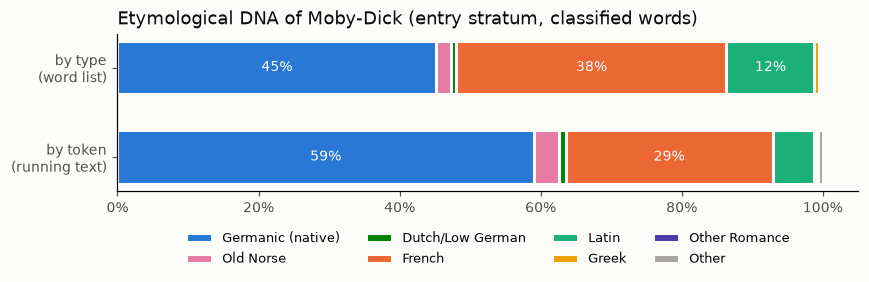

entry,Germanic (native),Old Norse,Dutch/Low German,French,Latin,Greek,Other Romance,Other
by type,45.2,2.1,0.7,38.3,12.5,0.7,0.2,0.3
by token,59.0,3.5,0.9,29.4,5.8,0.5,0.2,0.6


In [8]:
order = [s for s in STRATA if s in set(known.entry)]
profile = pd.DataFrame({
    "by type": known.entry.value_counts(normalize=True),
    "by token": known.groupby("entry").freq.sum() / known.freq.sum(),
}).reindex(order).fillna(0)

fig, ax = plt.subplots(figsize=(8, 2.8))
for i, col in enumerate(["by token", "by type"]):
    left = 0
    for s in order:
        v = profile.loc[s, col]
        ax.barh(i, v, left=left, color=COLORS[s], edgecolor=SURFACE, linewidth=2, height=0.6,
                label=s if i == 0 else None)
        if v > 0.06:
            ax.text(left + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white")
        left += v
ax.set_yticks([0, 1], ["by token\n(running text)", "by type\n(word list)"])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
style(ax, "Etymological DNA of Moby-Dick (entry stratum, classified words)", grid=None)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False, fontsize=8.5)
save(fig, "01_etymological_dna.png")
(profile * 100).round(1).T

In [9]:
pos_tab = (pd.crosstab(known.pos, known.entry, normalize="index") * 100).round(1)[order]
pos_tab["n words"] = known.pos.value_counts()
pos_tab

entry,Germanic (native),Old Norse,Dutch/Low German,French,Latin,Greek,Other Romance,Other,n words
pos,,,,,,,,,
ADJ,43.1,0.5,0.0,32.0,22.8,1.0,0.0,0.5,197
ADV,47.2,0.0,0.0,35.8,15.1,0.0,0.0,1.9,53
NOUN,44.9,2.2,1.2,41.8,8.4,1.2,0.4,0.0,510
VERB,46.6,3.4,0.6,37.0,12.0,0.0,0.0,0.3,324


**Part of speech and origin.** Following the instructor's feedback, I test whether origin depends on the part of speech, because POS could confound the topic comparison in H3: maritime words are almost all nouns. A χ² test on POS × (Germanic vs. Latinate) answers this.

In [10]:
gl_pos = known[known.entry.isin(["Germanic (native)"]) | known.latinate]
pos_ct = pd.crosstab(gl_pos.pos, gl_pos.latinate.map({True: "Latinate", False: "Germanic"}))
chi2_pos, p_pos, dof_pos, _ = stats.chi2_contingency(pos_ct)
POS = dict(chi2=chi2_pos, p=p_pos)
print(f"POS x origin (Germanic vs Latinate): chi2 = {chi2_pos:.2f}, df = {dof_pos}, p = {p_pos:.3f}")
(pos_ct.T / pos_ct.sum(axis=1)).T.round(3) * 100

POS x origin (Germanic vs Latinate): chi2 = 1.07, df = 3, p = 0.785


latinate,Germanic,Latinate
pos,,
ADJ,44.0,56.0
ADV,48.1,51.9
NOUN,47.0,53.0
VERB,48.7,51.3


### 4b. Frequency (H1)
The words are ranked by frequency and cut into 10 bands of 200 words. For each band I compute the share of **Latinate** words (French + Latin + Other Romance), then fit a **linear regression** of that share on the band's mean log frequency. At word level, a **point-biserial correlation** (Spearman) between log frequency and "is Latinate" gives a test with a p-value.

band regression: Latinate share = 0.96 + -0.34 * log10(freq)   R2 = 0.91, p = 0.0000
word level: Spearman rho(log freq, Latinate) = -0.229, p = 2.6e-14  (n = 1084)


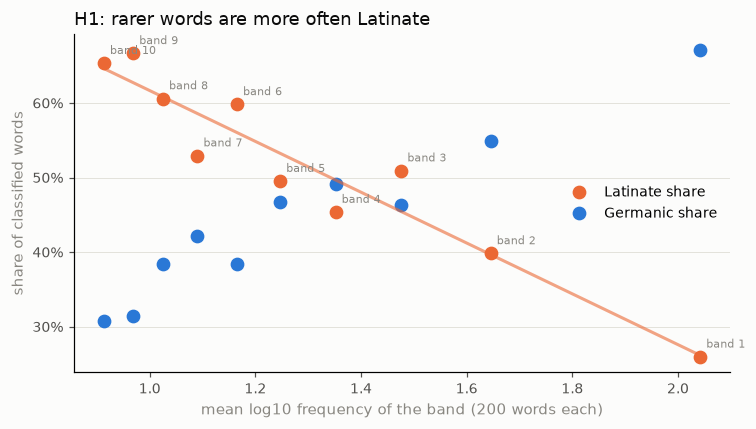

band,1,2,3,4,5,6,7,8,9,10
mean_logfreq,2.042,1.645,1.476,1.352,1.247,1.165,1.090,1.025,0.969,0.913
latinate,0.260,0.398,0.509,0.454,0.495,0.598,0.529,0.606,0.667,0.653
germanic,0.672,0.549,0.463,0.491,0.467,0.384,0.422,0.384,0.314,0.307
n,131.000,113.000,108.000,108.000,105.000,112.000,102.000,99.000,105.000,101.000


In [11]:
words["band"] = np.arange(len(words)) // 200 + 1
bands = known.assign(band=words.loc[known.index, "band"]).groupby("band").agg(
    mean_logfreq=("logfreq", "mean"), latinate=("latinate", "mean"),
    germanic=("entry", lambda s: (s == "Germanic (native)").mean()), n=("lemma", "size"))
reg = stats.linregress(bands.mean_logfreq, bands.latinate)
rho, p_rho = stats.spearmanr(known.logfreq, known.latinate)
H1 = dict(slope=reg.slope, r2=reg.rvalue ** 2, p_reg=reg.pvalue, rho=rho, p_rho=p_rho)
print(f"band regression: Latinate share = {reg.intercept:.2f} + {reg.slope:.2f} * log10(freq)   "
      f"R2 = {reg.rvalue**2:.2f}, p = {reg.pvalue:.4f}")
print(f"word level: Spearman rho(log freq, Latinate) = {rho:.3f}, p = {p_rho:.2g}  (n = {len(known)})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(bands.mean_logfreq, bands.latinate, "o", ms=8, color=COLORS["French"], label="Latinate share")
ax.plot(bands.mean_logfreq, bands.germanic, "o", ms=8, color=COLORS["Germanic (native)"], label="Germanic share")
xs = np.linspace(bands.mean_logfreq.min(), bands.mean_logfreq.max(), 10)
ax.plot(xs, reg.intercept + reg.slope * xs, color=COLORS["French"], lw=2, alpha=0.6)
for b, r in bands.iterrows():
    ax.annotate(f"band {b}", (r.mean_logfreq, r.latinate), xytext=(4, 6), textcoords="offset points", fontsize=7, color=MUTED)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
style(ax, "H1: rarer words are more often Latinate", "mean log10 frequency of the band (200 words each)",
      "share of classified words", grid="y")
ax.legend(frameon=False, fontsize=9)
save(fig, "02_frequency_regression.png")
bands.round(3).T

**Interpretation (H1).** The relation is clear and monotonic. Among the 200 most frequent content words only about a quarter are Latinate, while in the least frequent bands about two thirds are. The band-level regression explains about 90% of the variance (p < 0.001), and the word-level correlation is negative and highly significant. The same effect shows in Step 4a: the Germanic share is much higher **by token** (running text) than **by type** (word list), because the native words are the ones that are used again and again. **H1 is supported.** It matches the classic picture of English as a Germanic core (*man, sea, boat, see, go, hand*) surrounded by a large borrowed periphery.

### 4c. Maritime vocabulary (H3)
The maritime word set is defined by a fixed rule: the words of the list that appear in a hand-compiled **nautical and whaling glossary** (`data/nautical_glossary.txt`). That this vocabulary is topical in the novel is checked with **TF-IDF** over chapters (chapters as documents). The origin profile of the maritime words is then compared with the rest of the list. Seafaring loans (Old Norse + Dutch/Low German) are rare, so the prediction of H3 is tested with **Fisher's exact test** on a 2×2 table (maritime vs. general × seafaring vs. other origin), which is valid for small counts. The Germanic vs. Latinate contrast is tested with a **χ² test**.

In [12]:
glossary = {w.strip() for w in open("data/nautical_glossary.txt") if w.strip() and not w.startswith("#")}
words["maritime"] = words.lemma.isin(glossary)

docs = content.groupby("chapter").lemma.apply(" ".join)
tfidf = TfidfVectorizer(vocabulary=sorted(set(wordlist.lemma)), token_pattern=r"\S+")
M = tfidf.fit_transform(docs)
max_tfidf = pd.Series(M.max(axis=0).toarray().ravel(), index=tfidf.get_feature_names_out())
words["max_tfidf"] = words.lemma.map(max_tfidf)
print(f"{words.maritime.sum()} maritime words in the list; mean max-TF-IDF: maritime "
      f"{words[words.maritime].max_tfidf.mean():.3f} vs other {words[~words.maritime].max_tfidf.mean():.3f}")
print("most chapter-specific maritime words:",
      ", ".join(words[words.maritime].sort_values("max_tfidf", ascending=False).lemma.head(15)))

group = {"Germanic (native)": "Germanic", "Old Norse": "seafaring (Norse/Dutch)", "Dutch/Low German": "seafaring (Norse/Dutch)",
         "French": "Latinate", "Latin": "Latinate", "Other Romance": "Latinate", "Greek": "other", "Other": "other"}
kn = words[words.known].assign(group=lambda d: d.entry.map(group))
ct = pd.crosstab(kn.maritime.map({True: "maritime", False: "general"}), kn.group)
share = (ct.T / ct.sum(axis=1)).T * 100

sea = kn.group == "seafaring (Norse/Dutch)"
t2 = [[(kn.maritime & sea).sum(), (kn.maritime & ~sea).sum()], [(~kn.maritime & sea).sum(), (~kn.maritime & ~sea).sum()]]
odds, p_fisher = stats.fisher_exact(t2, alternative="greater")
gl = kn[kn.group.isin(["Germanic", "Latinate"])]
chi2, p_chi, dof, expected = stats.chi2_contingency(pd.crosstab(gl.maritime, gl.group))
H3 = dict(odds=odds, p=p_fisher, chi2=chi2, p_chi=p_chi, sea_mar=share.loc["maritime", "seafaring (Norse/Dutch)"],
          sea_gen=share.loc["general", "seafaring (Norse/Dutch)"], lat_mar=share.loc["maritime", "Latinate"],
          lat_gen=share.loc["general", "Latinate"])
print(f"seafaring loans: {H3['sea_mar']:.1f}% of maritime vs {H3['sea_gen']:.1f}% of general words; "
      f"Fisher exact (one-sided) odds ratio = {odds:.2f}, p = {p_fisher:.4f}")
print(f"Latinate: {H3['lat_mar']:.1f}% of maritime vs {H3['lat_gen']:.1f}% of general words; "
      f"chi2 (Germanic vs Latinate) = {chi2:.2f}, df = {dof}, p = {p_chi:.4f}")
display(ct)
share.round(1)

95 maritime words in the list; mean max-TF-IDF: maritime 0.202 vs other 0.130
most chapter-specific maritime words: oil, whale, spout, fish, log, line, shark, harpooneer, boat, chart, compass, pilot, cask, port, sea
seafaring loans: 9.8% of maritime vs 2.5% of general words; Fisher exact (one-sided) odds ratio = 4.21, p = 0.0127
Latinate: 29.4% of maritime vs 52.0% of general words; chi2 (Germanic vs Latinate) = 7.18, df = 1, p = 0.0074


group,Germanic,Latinate,other,seafaring (Norse/Dutch)
maritime,,,,
general,459,537,11,26
maritime,31,15,0,5


group,Germanic,Latinate,other,seafaring (Norse/Dutch)
maritime,,,,
general,44.4,52.0,1.1,2.5
maritime,60.8,29.4,0.0,9.8


**Controlling for part of speech.** Nearly all maritime words are nouns, so the comparison is repeated **within nouns only** (maritime nouns vs. other nouns). This removes a possible POS effect.

In [13]:
print("maritime words by POS:", dict(kn[kn.maritime].pos.value_counts()))
nn = kn[kn.pos == "NOUN"]
sea_n = nn.group == "seafaring (Norse/Dutch)"
t2n = [[(nn.maritime & sea_n).sum(), (nn.maritime & ~sea_n).sum()], [(~nn.maritime & sea_n).sum(), (~nn.maritime & ~sea_n).sum()]]
odds_n, p_fisher_n = stats.fisher_exact(t2n, alternative="greater")
gln = nn[nn.group.isin(["Germanic", "Latinate"])]
chi2_n, p_chi_n, _, _ = stats.chi2_contingency(pd.crosstab(gln.maritime, gln.group))
sh_n = pd.crosstab(nn.maritime.map({True: "maritime nouns", False: "other nouns"}), nn.group, normalize="index") * 100
H3.update(p_nouns=p_fisher_n, p_chi_nouns=p_chi_n)
print(f"within nouns - seafaring loans: Fisher odds ratio = {odds_n:.2f}, p = {p_fisher_n:.3f}; "
      f"Germanic vs Latinate: chi2 = {chi2_n:.2f}, p = {p_chi_n:.3f}")
sh_n.round(1)

maritime words by POS: {'NOUN': np.int64(46), 'VERB': np.int64(5)}
within nouns - seafaring loans: Fisher odds ratio = 3.30, p = 0.058; Germanic vs Latinate: chi2 = 4.77, p = 0.029


group,Germanic,Latinate,other,seafaring (Norse/Dutch)
maritime,,,,
maritime nouns,58.7,32.6,0.0,8.7
other nouns,43.5,52.4,1.3,2.8


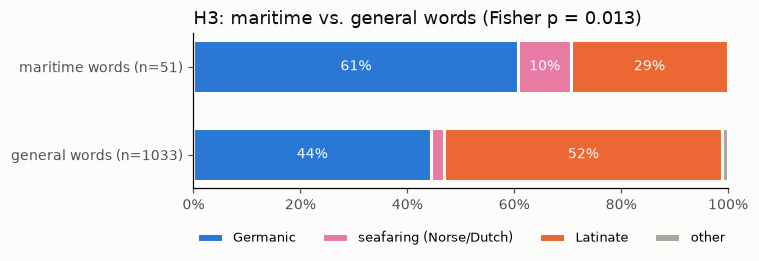

 lemma            entry                                             chain
  deck Dutch/Low German                                        dum:dekken
  keel        Old Norse                             enm:kele <- non:kjǫlr
cruise Dutch/Low German nld:kruisen <- nld:kruis <- dum:cruce <- lat:crux
  spar        Old Norse                          enm:sparre <- non:sparri
  boom Dutch/Low German                   nld:boom <- dum:boom <- odt:bom


In [14]:
fig, ax = plt.subplots(figsize=(7, 2.6))
gcols = {"Germanic": COLORS["Germanic (native)"], "seafaring (Norse/Dutch)": COLORS["Old Norse"],
         "Latinate": COLORS["French"], "other": COLORS["Other"]}
for i, row in enumerate(["general", "maritime"]):
    left = 0
    for g in gcols:
        v = share.loc[row, g] / 100 if g in share.columns else 0
        ax.barh(i, v, left=left, color=gcols[g], edgecolor=SURFACE, linewidth=2, height=0.6, label=g if i == 0 else None)
        if v > 0.05:
            ax.text(left + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white")
        left += v
ax.set_yticks([0, 1], [f"general words (n={ct.loc['general'].sum()})", f"maritime words (n={ct.loc['maritime'].sum()})"])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
style(ax, f"H3: maritime vs. general words (Fisher p = {p_fisher:.3f})", grid=None)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False, fontsize=8.5)
save(fig, "03_maritime.png")
print(words[words.maritime & words.entry.isin(["Old Norse", "Dutch/Low German"])][["lemma", "entry", "chain"]].to_string(index=False))

**Interpretation (H3).** TF-IDF confirms that the nautical words are topical, i.e. concentrated in particular chapters (mean maximum TF-IDF 0.20 vs. 0.13). Across the whole list, **seafaring loans (Old Norse, Dutch/Low German) are about four times more frequent among the maritime words** (*deck, keel, cruise, spar, boom*), and the one-sided Fisher test is significant. The instructor pointed out that part of speech may also be related to origin. In this data, the Germanic/Latinate split hardly differs between nouns, verbs, adjectives and adverbs (χ² not significant), so POS on its own does not drive origin. However, almost all maritime words are nouns, so the comparison was repeated **within nouns only**. There, the seafaring effect points the same way but becomes borderline (p ≈ 0.06), because only a handful of nouns are Norse or Dutch loans. **H3 is therefore partly supported:** the direction is as predicted, but the evidence is weak once POS is held constant. The second, unexpected result is more robust: maritime vocabulary is **more Germanic and much less Latinate** than general vocabulary, and this holds within nouns as well (χ² significant in both tests). The basic vocabulary of the sea (*ship, sea, boat, sail, oar, mast, line*) is old native vocabulary, supplemented by technical loans from the North-Sea neighbours rather than from learned Latin. Melville's whaling world is, linguistically, a Germanic world.

## Step 5. Chapters as etymological profiles (H2)

Every chapter becomes a vector: the token-weighted shares of each stratum among its classified content words. The 135 vectors are reduced to two dimensions with **PCA** and clustered with **k-means** and **hierarchical (Ward) clustering** into two groups. The clusters are compared with the narrative/expository labels from Step 1 using the adjusted Rand index (ARI). The Latinate share of the two chapter types is compared with a one-sided **Mann–Whitney U test**.

In [15]:
ent = dict(zip(words.lemma, words.entry))
ct_tok = content.assign(entry=content.lemma.map(ent)).dropna(subset=["entry"])
ct_tok = ct_tok[ct_tok.entry != "unknown"]
prof = pd.crosstab(ct_tok.chapter, ct_tok.entry, normalize="index").reindex(columns=order, fill_value=0)
chap = chap.join(prof)
chap["latinate"] = prof[[c for c in prof.columns if c in LATINATE]].sum(axis=1)
chap["classified_tokens"] = ct_tok.groupby("chapter").size()

X = StandardScaler().fit_transform(prof)
pca = PCA(n_components=2, random_state=0).fit(X)
chap[["pc1", "pc2"]] = pca.transform(X)
chap["kmeans"] = KMeans(n_clusters=2, n_init=20, random_state=0).fit_predict(X)
chap["ward"] = fcluster(linkage(X, "ward"), 2, "maxclust")
is_exp = (chap.type == "expository").astype(int)
ari_km, ari_ward = adjusted_rand_score(is_exp, chap.kmeans), adjusted_rand_score(is_exp, chap.ward)
u, p_u = stats.mannwhitneyu(chap.loc[chap.type == "expository", "latinate"],
                            chap.loc[chap.type == "narrative", "latinate"], alternative="greater")
med = chap.groupby("type").latinate.median()
H2 = dict(u=u, p=p_u, med_exp=med["expository"], med_nar=med["narrative"], ari_km=ari_km, ari_ward=ari_ward)
print(f"PCA explained variance: {pca.explained_variance_ratio_.round(3)}")
print("PC1 loadings:", dict(zip(prof.columns, pca.components_[0].round(2))))
print(f"median Latinate share: expository {med['expository']:.1%} vs narrative {med['narrative']:.1%}; "
      f"Mann-Whitney U = {u:.0f}, one-sided p = {p_u:.2g}")
print(f"agreement of clusters with the chapter labels: ARI k-means = {ari_km:.2f}, ARI Ward = {ari_ward:.2f}")
print(pd.crosstab(chap.type, chap.kmeans, colnames=["k-means cluster"]))

PCA explained variance: [0.327 0.155]
PC1 loadings: {'Germanic (native)': np.float64(-0.55), 'Old Norse': np.float64(-0.23), 'Dutch/Low German': np.float64(-0.14), 'French': np.float64(0.56), 'Latin': np.float64(0.52), 'Greek': np.float64(0.06), 'Other Romance': np.float64(-0.14), 'Other': np.float64(-0.14)}
median Latinate share: expository 44.0% vs narrative 32.3%; Mann-Whitney U = 2908, one-sided p = 1.8e-10
agreement of clusters with the chapter labels: ARI k-means = 0.31, ARI Ward = 0.24
k-means cluster   0   1
type                   
expository        6  27
narrative        79  23


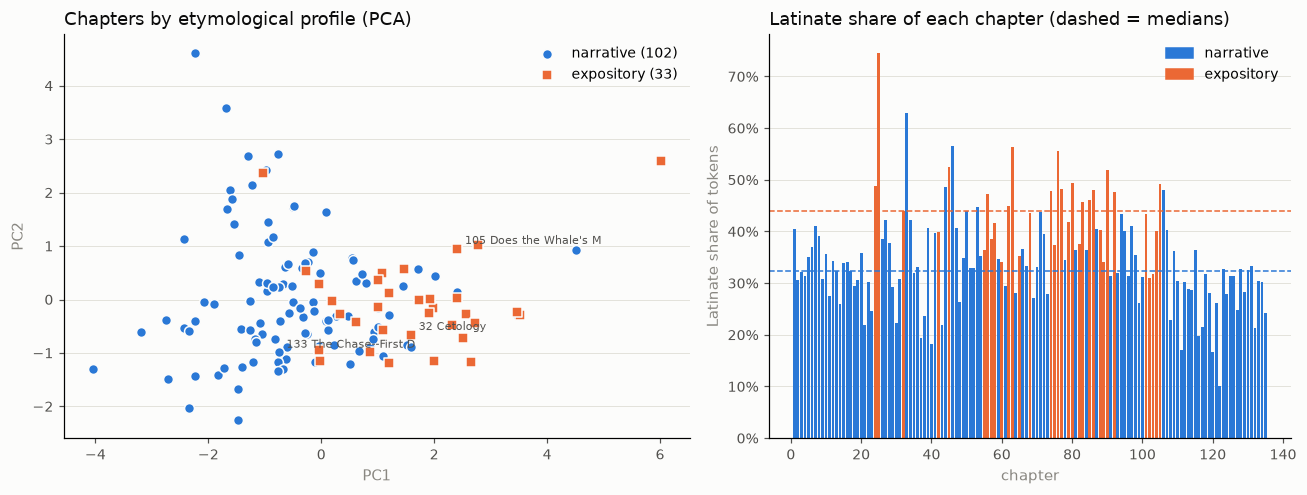

,title,type,latinate
chapter,,,
25,Postscript.,expository,0.744681
33,The Specksynder.,narrative,0.628571
46,Surmises.,narrative,0.566176
63,The Crotch.,expository,0.563107
76,The Battering-Ram.,expository,0.555556
45,The Affidavit.,expository,0.523967
90,Heads or Tails.,expository,0.518072
80,The Nut.,expository,0.493333
105,Does the Whale's Magnitude Diminish?--Will He Perish?,expository,0.491379


In [16]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
for t, c, m in [("narrative", COLORS["Germanic (native)"], "o"), ("expository", COLORS["French"], "s")]:
    d = chap[chap.type == t]
    a1.scatter(d.pc1, d.pc2, s=42, color=c, marker=m, edgecolors=SURFACE, linewidths=1, label=f"{t} ({len(d)})", zorder=3)
for n in [32, 105, 133]:
    a1.annotate(f"{n} {chap.loc[n, 'title'][:18].rstrip('.-')}", (chap.loc[n, "pc1"], chap.loc[n, "pc2"]), fontsize=7,
                color=INK2, xytext=(5, 3), textcoords="offset points")
style(a1, "Chapters by etymological profile (PCA)", "PC1", "PC2", grid="y")
a1.legend(frameon=False, fontsize=9)

a2.bar(chap.index, chap.latinate, color=[COLORS["French"] if t == "expository" else COLORS["Germanic (native)"]
                                          for t in chap.type], width=0.8)
a2.axhline(med["narrative"], color=COLORS["Germanic (native)"], lw=1, ls="--")
a2.axhline(med["expository"], color=COLORS["French"], lw=1, ls="--")
a2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
style(a2, "Latinate share of each chapter (dashed = medians)", "chapter", "Latinate share of tokens", grid="y")
from matplotlib.patches import Patch
a2.legend(handles=[Patch(color=COLORS["Germanic (native)"], label="narrative"), Patch(color=COLORS["French"], label="expository")],
          frameon=False, fontsize=9, loc="upper right")
save(fig, "04_chapters.png")
chap.sort_values("latinate", ascending=False)[["title", "type", "latinate"]].head(10)

**Interpretation (H2).** The first principal component is an etymological axis: Germanic (and Norse) loadings are negative, French and Latin loadings positive. The expository chapters lie mostly on the Latinate side, their median Latinate share is about 12 percentage points higher than that of the narrative chapters, and the Mann–Whitney test is highly significant. **H2 is supported.** The unsupervised clusters agree with the labels only partly (ARI ≈ 0.2–0.3). k-means puts most expository chapters in one cluster, but it also adds a group of narrative chapters with a reflective, essay-like style (e.g. *The Specksynder*, *Surmises*, which are among the most Latinate chapters of the whole book). At the other end, the least Latinate chapters are the short, play-like **dramatic scenes** written as dialogue and monologue (*Midnight Aloft.—Thunder and Lightning*, *Midnight, Forecastle*, *Sunset*, *The Deck Towards the End of the First Night Watch*), and the third day of the final chase is also among the 15 most Germanic chapters. Etymology therefore tracks **register** (argument vs. speech and action) rather than simply the narrative/expository label: Melville's prose becomes Latinate when he argues and Germanic when his characters speak and act.

## Step 6. The ancestry network (H4, exploratory extension)

*As suggested in the feedback on the proposal, this step is treated as an exploratory extension: it looks at historical routes rather than at Melville's text, so it is reported more briefly and does not carry the main conclusions.*

All chains are merged into one **directed graph**: English word → ancestor → … → oldest ancestor. A node is a (language, word) pair, e.g. *fro:capitaine*, and shared ancestors join different English words. For this **term graph** I compute size, density, components and the most productive ancestors (highest in-degree; affixes excluded).

A second, **language-level** graph aggregates the same links between languages (e.g. English → Old French → Latin, weighted by the number of links) and shows the *routes* by which words reached English. Here **betweenness centrality** identifies the bridge languages. **Greedy-modularity communities** of the language graph are compared with the language families (Germanic / Romance–Latin / Greek / other) using normalised mutual information (NMI).

In [17]:
G = nx.DiGraph()
for r in records:
    prev = ("en", r["word"])
    G.add_node(prev, lang="en", stratum="English")
    for c in r["chain"]:
        node = (c["lang"], c["term"])
        G.add_node(node, lang=c["lang"], stratum=stratum_of_code(c["lang"]))
        if prev != node:
            G.add_edge(prev, node)
        prev = node
G.remove_nodes_from([n for n in list(G) if G.degree(n) == 0])
U = G.to_undirected()
print(f"term graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges, density {nx.density(G):.5f}, "
      f"{nx.number_connected_components(U)} components (largest: {len(max(nx.connected_components(U), key=len))} nodes)")

comp_sizes = collections.Counter(len(c) for c in nx.connected_components(U))
print("component sizes (size: how many):", dict(sorted(comp_sizes.items())))
indeg = sorted(((n, d) for n, d in G.in_degree() if not (n[1].startswith("-") or n[1].endswith("-"))), key=lambda x: -x[1])[:12]
print("most productive ancestors (in-degree):", ", ".join(f"{lang_name(l)} {t} ({d})" for (l, t), d in indeg))
for comp in sorted(nx.connected_components(U), key=len, reverse=True)[:3]:
    eng = sorted(t for l, t in comp if l in ("en", "eng"))[:12]
    roots = [f"{lang_name(l)} {t}" for l, t in comp if G.out_degree((l, t)) == 0][:4]
    print(f"  component of {len(comp)} nodes - English words: {', '.join(eng)} | roots: {', '.join(roots)}")

term graph: 3857 nodes, 2505 edges, density 0.00017, 1352 components (largest: 13 nodes)
component sizes (size: how many): {2: 675, 3: 401, 4: 154, 5: 82, 6: 21, 7: 11, 8: 3, 9: 2, 10: 2, 13: 1}
most productive ancestors (in-degree): Middle English owen (3), Middle English man (2), Middle English hed (2), Middle English water (2), Old French crier (2), Middle English whit (2), Middle English leten (2), Old English fiscian (2), Middle English callen (2), Old French harpon (2), Middle English ende (2), Middle English feele (2)
  component of 13 nodes - English words: mystery, mystic, mystic, mystical | roots: Ancient Greek μύω
  component of 10 nodes - English words: pay, peace, piece | roots: Latin pax
  component of 10 nodes - English words: character, chart | roots: Ancient Greek χαράσσω


In [18]:
L = nx.DiGraph()
for r in records:
    langs = ["en"] + [c["lang"] for c in r["chain"]]
    names = [lang_name(l) for l in langs]
    for a, b in zip(names, names[1:]):
        if a != b:
            L.add_edge(a, b, weight=L.get_edge_data(a, b, {"weight": 0})["weight"] + 1)
for n in L:
    L.nodes[n]["terms"] = sum(1 for _, d in G.nodes(data=True) if lang_name(d["lang"]) == n)
btw = nx.betweenness_centrality(L)                    # unweighted: which languages lie on the routes
lang_tab = pd.DataFrame({"terms": nx.get_node_attributes(L, "terms"), "betweenness": btw,
                         "in links": dict(L.in_degree(weight="weight")),
                         "out links": dict(L.out_degree(weight="weight"))}).sort_values("betweenness", ascending=False)
NAME2STRATUM = {nm: st for nm, st in LANGUAGES.values()}
FAMILY = {"Germanic (native)": "Germanic", "Old Norse": "Germanic", "Dutch/Low German": "Germanic",
          "French": "Romance/Latin", "Latin": "Romance/Latin", "Other Romance": "Romance/Latin", "Greek": "Greek"}
main_langs = [n for n in L if n != "English" and L.nodes[n]["terms"] >= 3]
LU = nx.Graph()
for u, v, d in L.subgraph(main_langs).edges(data=True):
    LU.add_edge(u, v, weight=LU.get_edge_data(u, v, {"weight": 0})["weight"] + d["weight"])
lcomms = nx_comm.greedy_modularity_communities(LU, weight="weight")
Q = nx_comm.modularity(LU, lcomms, weight="weight")
lcid = {n: i for i, c in enumerate(lcomms) for n in c}
fam = {n: FAMILY.get(NAME2STRATUM.get(n, "Other"), "other") for n in LU}
nmi = normalized_mutual_info_score([fam[n] for n in LU], [lcid[n] for n in LU])
bridges = [b for b in lang_tab.index if b != "English" and L.nodes[b]["terms"] >= 3][:3]
H4 = dict(Q=Q, nmi=nmi, n_comms=len(lcomms), bridges=bridges)
print("main bridges between English and older languages (betweenness):", bridges)
for i, c in enumerate(lcomms):
    print(f"  community {i + 1}: " + ", ".join(f"{n} [{fam[n]}]" for n in sorted(c, key=lambda n: -L.nodes[n]["terms"])))
print(f"language graph: {len(lcomms)} communities, modularity Q = {Q:.2f}, NMI with language families = {nmi:.2f}")
lang_tab[lang_tab.terms >= 3].round(3)

main bridges between English and older languages (betweenness): ['Old French', 'Ancient Greek', 'Middle Dutch']
  community 1: Latin [Romance/Latin], Old French [Romance/Latin], Ancient Greek [Greek], French [Romance/Latin], Middle French [Romance/Latin], Italian [Romance/Latin], Spanish [Romance/Latin]
  community 2: Middle English [other], Old English [Germanic], Anglo-Norman [Romance/Latin], Old Norse [Germanic]
  community 3: Middle Dutch [Germanic], Dutch [Germanic]
language graph: 3 communities, modularity Q = 0.27, NMI with language families = 0.53


,terms,betweenness,in links,out links
Old French,261,0.055,274,178
Ancient Greek,69,0.052,48,1
Middle Dutch,8,0.041,8,3
Latin,488,0.041,383,37
French,53,0.027,52,34
Middle French,49,0.017,49,33
Italian,12,0.015,10,5
Spanish,3,0.015,3,1
Old English,453,0.006,490,23
Old Norse,26,0.000,25,0


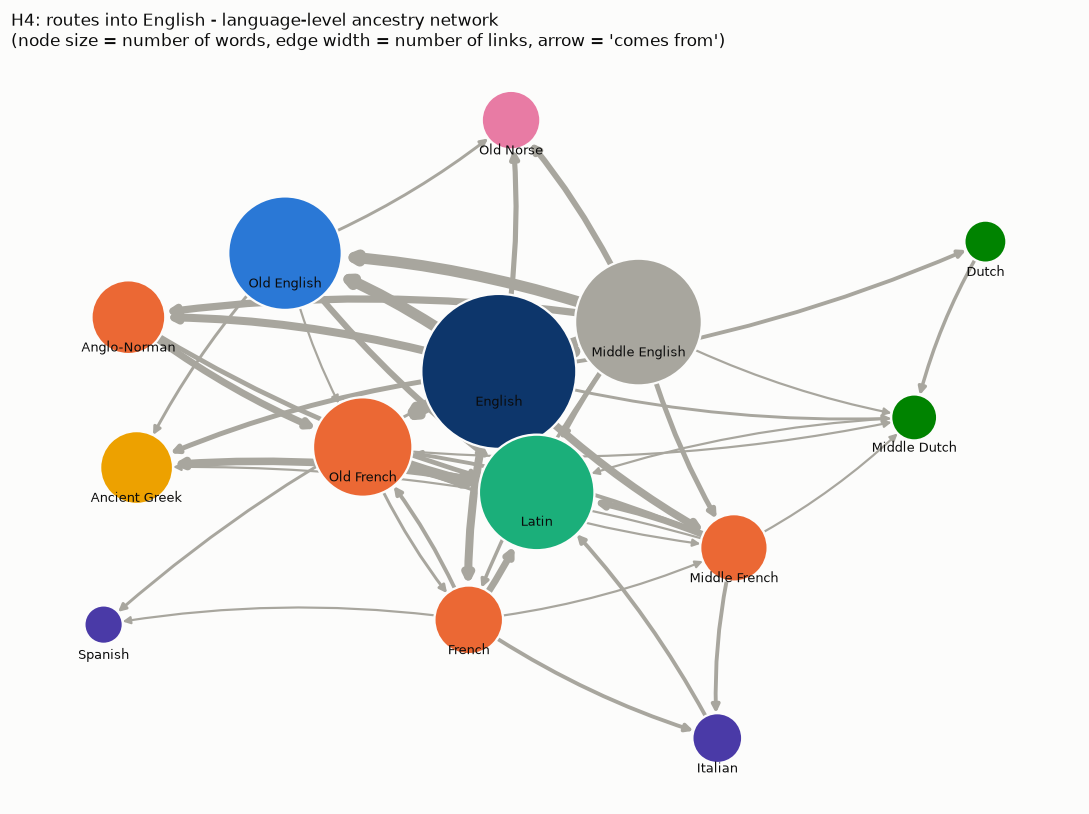

In [19]:
main = [n for n in L if L.nodes[n]["terms"] >= 3 or n == "English"]
Ls = L.subgraph(main).copy()
pos = nx.kamada_kawai_layout(Ls.to_undirected(), weight=None)
fig, ax = plt.subplots(figsize=(10, 7.5))
NAME2STRATUM = {nm: st for nm, st in LANGUAGES.values()}
ncol = ["#0d366b" if n == "English" else COLORS.get(NAME2STRATUM.get(n, "Other"), COLORS["Other"]) for n in Ls]
w = [Ls[u][v]["weight"] for u, v in Ls.edges]
nx.draw_networkx_edges(Ls, pos, ax=ax, width=[0.6 + 1.2 * math.log1p(x) for x in w], edge_color="#a8a69e",
                       arrows=True, arrowstyle="-|>", arrowsize=10, node_size=[200 + 25 * math.sqrt(Ls.nodes[n]["terms"]) * 10 for n in Ls],
                       connectionstyle="arc3,rad=0.08")
nx.draw_networkx_nodes(Ls, pos, ax=ax, node_color=ncol,
                       node_size=[200 + 25 * math.sqrt(Ls.nodes[n]["terms"]) * 10 for n in Ls], edgecolors=SURFACE, linewidths=1.5)
for n, (x, y) in pos.items():
    ax.text(x, y - 0.075, n, ha="center", va="top", fontsize=8.5, color=INK)
ax.set_title("H4: routes into English - language-level ancestry network\n(node size = number of words, edge width = number of links, arrow = 'comes from')",
             loc="left", fontsize=11, color=INK)
ax.axis("off")
save(fig, "05_language_network.png")

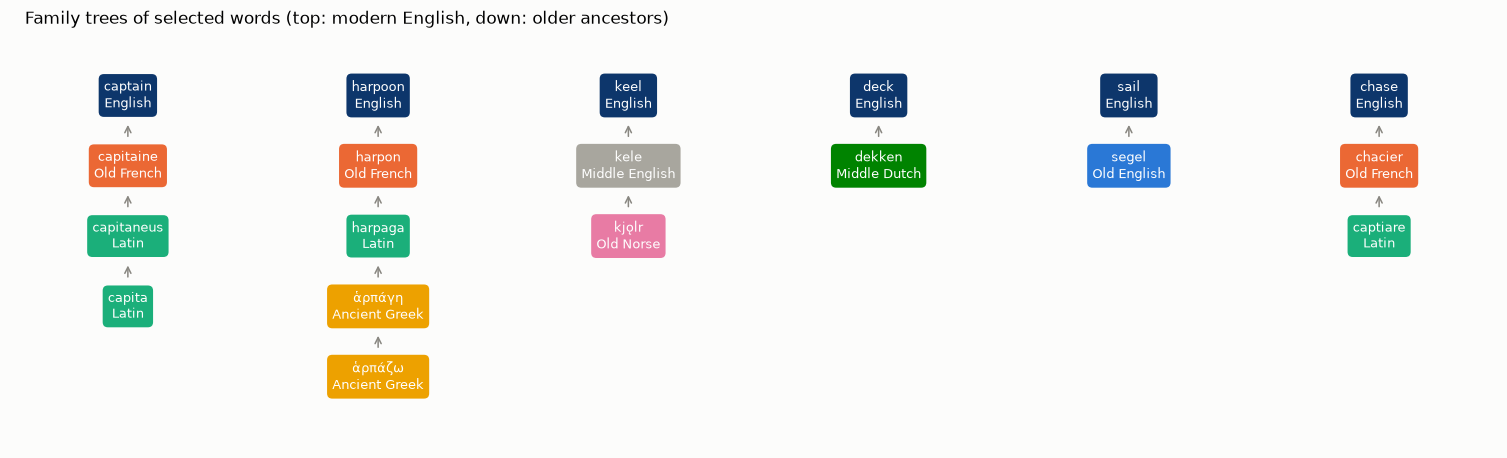

In [20]:
# family trees of a few words, drawn from the crawled/fallback chains
examples = [w for w in ["whale", "captain", "harpoon", "keel", "deck", "sail", "chase", "skipper", "sky"]
            if w in by_word and by_word[w]["chain"]][:6]
fig, axes = plt.subplots(1, len(examples), figsize=(2.3 * len(examples), 4.2))
for ax, w in zip(np.atleast_1d(axes), examples):
    steps = [("English", w)] + [(lang_name(c["lang"]), c["term"]) for c in by_word[w]["chain"]]
    for i, (l, t) in enumerate(steps):
        code_ = "en" if i == 0 else by_word[w]["chain"][i - 1]["lang"]
        col = "#0d366b" if i == 0 else COLORS.get(stratum_of_code(code_), COLORS["Other"])
        ax.text(0.5, 1 - i * 0.16, f"{t}\n{l}", ha="center", va="center", fontsize=8.5, color="white",
                bbox=dict(boxstyle="round,pad=0.4", fc=col, ec="none"))
        if i:
            ax.annotate("", (0.5, 1 - i * 0.16 + 0.06), (0.5, 1 - (i - 1) * 0.16 - 0.06),
                        arrowprops=dict(arrowstyle="<-", color=MUTED))
    ax.set_xlim(0, 1); ax.set_ylim(1 - 0.16 * max(5, len(steps)), 1.1); ax.axis("off")
fig.suptitle("Family trees of selected words (top: modern English, down: older ancestors)", x=0.02, ha="left", fontsize=11)
save(fig, "06_family_trees.png")

**Interpretation (H4).** The term graph is very fragmented: most words have their own short chain, and only a few English words meet at a shared ancestor (*pay, peace, piece* at Latin *pax*; *character, chart* at Greek). At the depth available in the data, the vocabulary is a forest of separate lineages rather than one network. The language-level graph is more informative. **Old French has the highest betweenness**: it is the main bridge through which Latin (and some Greek) material reached English, while Latin is the largest pool of ultimate ancestors. Its communities correspond to language families (NMI ≈ 0.5): a Romance–Latin–Greek community, the English line (Old/Middle English together with Old Norse and Anglo-Norman), and a small Dutch community. Anglo-Norman falls into the English community because it was the French *spoken in England* and entered the language directly through Middle English. Modularity is moderate (Q ≈ 0.27, below the 0.3 threshold), so **H4 is partly supported**: the bridge prediction holds, and the community structure is real but not sharp.

## Step 7. Predicting origin: form vs. meaning (H5)

Can a word's origin be guessed from the word alone? The classes are the strata with at least 20 classified words, compared in two ways:

* **Form:** character n-grams (2–4 letters, with word boundaries) of the spelling, **TF-IDF**-weighted, plus a logistic-regression classifier;
* **Meaning:** **word2vec** vectors trained on the 18 Project Gutenberg books of the NLTK corpus (~2.6 M words, *Moby-Dick* included), with the same classifier.

Both are evaluated with stratified 5-fold cross-validation against a majority-class baseline (accuracy and macro-F1).

In [21]:
cls_counts = known.entry.value_counts()
CLASSES = [c for c in cls_counts.index if cls_counts[c] >= 20]
data7 = known[known.entry.isin(CLASSES)].reset_index(drop=True)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
scoring = ["accuracy", "f1_macro"]
def evaluate(model, X, y):
    s = cross_validate(model, X, y, cv=cv, scoring=scoring)
    return {m: s[f"test_{m}"].mean() for m in scoring}

form_model = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True),
                           LogisticRegression(max_iter=3000, class_weight="balanced", C=3))
res = {"baseline (majority class)": evaluate(DummyClassifier(strategy="most_frequent"), data7.lemma, data7.entry),
       "form: char n-gram TF-IDF": evaluate(form_model, data7.lemma, data7.entry)}
print("classes:", dict(data7.entry.value_counts()))

form_model.fit(data7.lemma, data7.entry)
vec, clf = form_model.named_steps.values()
feats = vec.get_feature_names_out()
for k, c in enumerate(clf.classes_):
    top = feats[np.argsort(clf.coef_[k])[::-1][:12]]
    print(f"  most typical letter sequences for {c:<18}: {' '.join(repr(t) for t in top)}")

classes: {'Germanic (native)': np.int64(490), 'French': np.int64(415), 'Latin': np.int64(135), 'Old Norse': np.int64(23)}


  most typical letter sequences for French            : ' p' 're' 'ge ' ' re' 'ce' 'y ' 'nce ' 'er ' 'age ' 'ur' 'ce ' 'co'
  most typical letter sequences for Germanic (native) : 'd ' ' w' 'ea' 'll ' 'h ' 'p ' ' h' 'he' ' b' 'th' 'm ' ' t'
  most typical letter sequences for Latin             : 'ct ' 'ct' 'ns' ' i' 'ect' ' in' 'en' 'ec' 'ect ' 'id' 'al' 'te'
  most typical letter sequences for Old Norse         : 'g ' ' rat' 'ag ' 'cast' 'par ' ' ra' 'cra' 'say' 'say ' ' say' 'ak' 'wan'


In [22]:
def sentences(path):
    text = open(path, encoding="utf-8", errors="ignore").read().lower()
    for s in re.split(r"[.!?;:]\s+", text):
        toks = re.findall(r"[a-z]+", s)
        if len(toks) > 2:
            yield toks
corpus = [s for f in sorted(os.listdir("data/gutenberg")) for s in sentences(f"data/gutenberg/{f}")]
w2v = Word2Vec(corpus, vector_size=100, window=5, min_count=5, sg=1, epochs=10, seed=1, workers=1)
print(f"word2vec trained on {sum(map(len, corpus)):,} tokens, vocabulary {len(w2v.wv):,}")

in_vocab = data7[data7.lemma.isin(w2v.wv.key_to_index)].reset_index(drop=True)
Xm = np.vstack([w2v.wv[w] for w in in_vocab.lemma])
meaning_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced", C=0.1))
res["meaning: word2vec"] = evaluate(meaning_model, Xm, in_vocab.entry)
res["form (same words as word2vec)"] = evaluate(form_model, in_vocab.lemma, in_vocab.entry)
res_tab = pd.DataFrame(res).T.round(3)
H5 = dict(form=res["form: char n-gram TF-IDF"]["f1_macro"], meaning=res["meaning: word2vec"]["f1_macro"],
          base=res["baseline (majority class)"]["f1_macro"])
print(f"{len(in_vocab)} of {len(data7)} words have a word2vec vector")
res_tab

word2vec trained on 2,128,251 tokens, vocabulary 15,416


1046 of 1063 words have a word2vec vector


,accuracy,f1_macro
baseline (majority class),0.461,0.158
form: char n-gram TF-IDF,0.692,0.486
meaning: word2vec,0.463,0.357
form (same words as word2vec),0.709,0.500


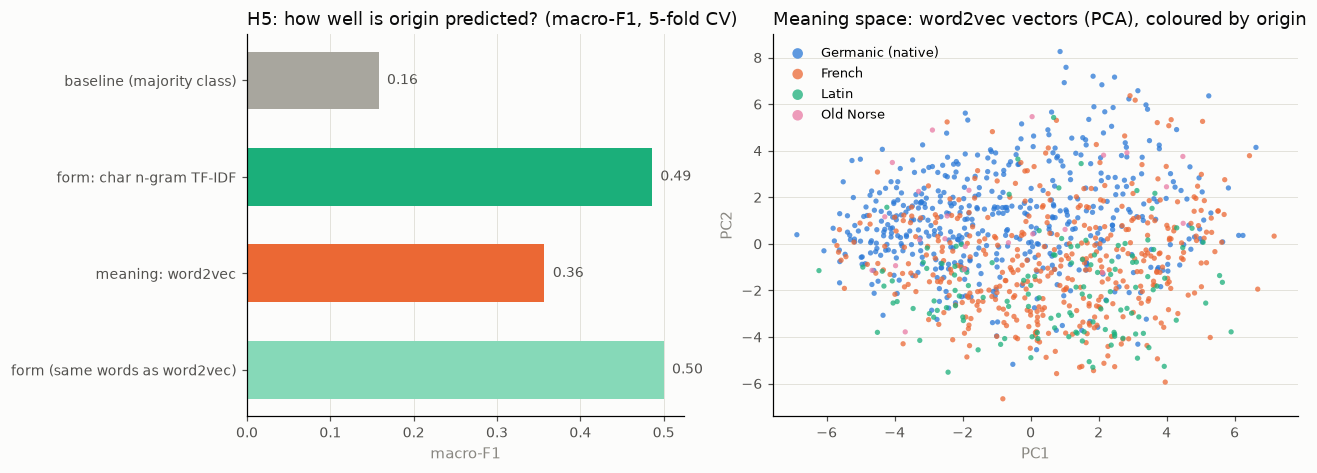

In [23]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.2]})
names = list(res_tab.index)
a1.barh(names[::-1], res_tab.f1_macro[::-1], color=["#a8a69e", COLORS["Latin"], COLORS["French"], "#86d9b8"][::-1], height=0.6)
for i, v in enumerate(res_tab.f1_macro[::-1]):
    a1.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9, color=INK2)
style(a1, "H5: how well is origin predicted? (macro-F1, 5-fold CV)", "macro-F1")
emb = PCA(n_components=2, random_state=0).fit_transform(StandardScaler().fit_transform(Xm))
for c in CLASSES:
    m = (in_vocab.entry == c).values
    a2.scatter(emb[m, 0], emb[m, 1], s=12, color=COLORS[c], alpha=0.75, label=c, edgecolors="none")
style(a2, "Meaning space: word2vec vectors (PCA), coloured by origin", "PC1", "PC2", grid="y")
a2.legend(frameon=False, fontsize=8.5, markerscale=2)
save(fig, "07_form_vs_meaning.png")

**Interpretation (H5).** Spelling alone predicts the entry stratum far above the baseline (macro-F1 ≈ 0.49 vs. 0.16). The most typical letter sequences are textbook markers: *-ce, -age, -ment, re-* for French; *-ct, -ns, in-* for Latin; *th, w-, -ll, ea* for native words. Meaning, represented by word2vec vectors, also carries some signal (≈ 0.36): in the PCA plot, Latin and French words lean towards one region of the semantic space (abstract, learned vocabulary). But meaning is clearly weaker than form, and the comparison on exactly the same words confirms this. **H5 is supported.** A word's history is written into its spelling more reliably than into its use.

## Summary of results

The table is computed from the results above. A hypothesis counts as **supported** if the test is significant (p < 0.05) *and* goes in the predicted direction.

In [24]:
def verdict(ok, partly=False):
    return "supported" if ok else ("partly supported" if partly else "not supported")
summary = pd.DataFrame([
    ["H1 frequency", f"Spearman rho = {H1['rho']:.2f} (p = {H1['p_rho']:.2g}); band regression slope = {H1['slope']:.2f}, R2 = {H1['r2']:.2f}",
     verdict(H1["rho"] < 0 and H1["p_rho"] < 0.05)],
    ["H2 style", f"median Latinate share expository {H2['med_exp']:.0%} vs narrative {H2['med_nar']:.0%}; U-test p = {H2['p']:.2g}; ARI k-means = {H2['ari_km']:.2f}",
     verdict(H2["med_exp"] > H2["med_nar"] and H2["p"] < 0.05)],
    ["H3 topic", f"seafaring loans {H3['sea_mar']:.0f}% of maritime vs {H3['sea_gen']:.0f}% of general words (Fisher p = {H3['p']:.2g}; nouns only p = {H3['p_nouns']:.2g}); Latinate {H3['lat_mar']:.0f}% vs {H3['lat_gen']:.0f}% (chi2 p = {H3['p_chi']:.2g}; nouns only p = {H3['p_chi_nouns']:.2g})",
     verdict(H3["p"] < 0.05 and H3["sea_mar"] > H3["sea_gen"] and H3["p_nouns"] < 0.05,
             partly=H3["p"] < 0.05 or H3["p_chi"] < 0.05)],
    ["POS (feedback)", f"POS x origin: chi2 = {POS['chi2']:.1f}, p = {POS['p']:.2g}", "no POS effect" if POS["p"] >= 0.05 else "POS effect"],
    ["H4 network", f"language graph: {H4['n_comms']} communities, Q = {H4['Q']:.2f}, NMI with families = {H4['nmi']:.2f}; bridges: {', '.join(H4['bridges'])}",
     verdict(H4["Q"] > 0.3 and H4["nmi"] > 0.3 and any(b in ("Old French", "Latin", "Middle French", "Anglo-Norman") for b in H4["bridges"]),
             partly=H4["nmi"] > 0.3 or any(b in ("Old French", "Latin") for b in H4["bridges"]))],
    ["H5 form vs meaning", f"macro-F1: form {H5['form']:.2f}, meaning {H5['meaning']:.2f}, baseline {H5['base']:.2f}",
     verdict(H5["form"] > H5["meaning"] > H5["base"] or (H5["form"] > H5["meaning"] and H5["form"] > H5["base"]))],
], columns=["hypothesis", "evidence", "result"])
print("data source:", SOURCE)
summary.style.hide(axis="index")

data source: Etymological WordNet (Wiktionary-derived offline fallback)


hypothesis,evidence,result
H1 frequency,"Spearman rho = -0.23 (p = 2.6e-14); band regression slope = -0.34, R2 = 0.91",supported
H2 style,median Latinate share expository 44% vs narrative 32%; U-test p = 1.8e-10; ARI k-means = 0.31,supported
H3 topic,seafaring loans 10% of maritime vs 3% of general words (Fisher p = 0.013; nouns only p = 0.058); Latinate 29% vs 52% (chi2 p = 0.0074; nouns only p = 0.029),partly supported
POS (feedback),"POS x origin: chi2 = 1.1, p = 0.79",no POS effect
H4 network,"language graph: 3 communities, Q = 0.27, NMI with families = 0.53; bridges: Old French, Ancient Greek, Middle Dutch",partly supported
H5 form vs meaning,"macro-F1: form 0.49, meaning 0.36, baseline 0.16",supported


## Conclusions

**Three of the five hypotheses are supported and two are partly supported** (H3, once part of speech is controlled for, and the exploratory network hypothesis H4). The etymological make-up of *Moby-Dick* is not uniform. It depends on **frequency** (the more frequent a word, the more likely it is native Germanic), on **register** (essay-like whale-science chapters are markedly more Latinate than narrative ones, while the dramatic, dialogue-based scenes are the most Germanic) and on **topic** (the vocabulary of the sea is native Germanic plus a few North-Sea loans, not Latin; the Germanic result survives a control for part of speech, the North-Sea-loan result only weakly). Historically, the network of ancestors shows **Old French as the main gateway** into English. Computationally, a word's origin is **recoverable from its spelling much better than from its meaning**.

**What the project contributes.** A reusable pipeline from crawler to SQLite database to analysis, which turns Wiktionary into an etymological annotation layer for any English text. The same pipeline can be pointed at other authors, periods or languages.

**Limitations.**
* *Data source and coverage.* The analysis uses the source printed in the summary. Without a full live crawl, only about half the word list is classified, and the offline data contain some wrong links. The manual check (≈ 85% agreement) shows that errors are mostly French-vs-Latin confusions, so the Germanic/Latinate results are robust, but the finer strata are less reliable.
* Homographs (*seal*) receive their first etymology only; the lemmatizer is trained on modern English.
* The narrative/expository labels and the manual check were made by one annotator; the nautical glossary is a fixed hand-made list.
* The word2vec model is trained on a small corpus (2.1 M tokens), so the meaning-based results are a lower bound.

**Future work.** Complete the live crawl, add borrowing *dates* to model the chronology of the layers, compare Melville with other 19th-century authors, and apply the method to the Persian, Arabic and Indic layers of Urdu.